# 00 · Data tour — what are we actually predicting?

Before building any model, we look at the target: **FPL points per player per fixture**.
Four questions shape the whole model design:

1. How often do players not play at all? (the *minutes* problem)
2. What does the distribution of points look like? (why we predict a *distribution*, not one number)
3. Where do points come from, by position? (which *components* matter most)
4. How predictable is next week from recent weeks? (how hard is this, and what's the bar to beat)

Data: `core.player_match_stats`, seasons **2022-23 onwards** (the period we agreed to train on).

In [1]:
import sys, warnings; sys.path.insert(0, '..'); warnings.filterwarnings('ignore', message='pandas only supports SQLAlchemy')
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from fpl_engine import db
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.spines.top': False, 'axes.spines.right': False})
POS_ORDER = ['GKP', 'DEF', 'MID', 'FWD']

with db.connect() as conn:
    df = pd.read_sql('''
        SELECT s.*, ps.position, f.official_home_fdr, f.official_away_fdr
        FROM core.player_match_stats s
        JOIN core.player_seasons ps ON ps.player_id = s.player_id AND ps.season = s.season
        JOIN core.fixtures f ON f.fixture_id = s.fixture_id
        WHERE s.season >= '2022-23' AND ps.position IN ('GKP','DEF','MID','FWD')
    ''', conn)
df['played'] = df.minutes > 0
df['fdr'] = np.where(df.was_home, df.official_home_fdr, df.official_away_fdr)
print(f"{len(df):,} player-fixture rows, {df.player_id.nunique():,} players, seasons {sorted(df.season.unique())}")

120,496 player-fixture rows, 1,721 players, seasons ['2022-23', '2023-24', '2024-25', '2025-26', '2026-27']


## 1 · The minutes problem

A row exists for **every squad player for every fixture**, including those who never left the bench (or the treatment room).

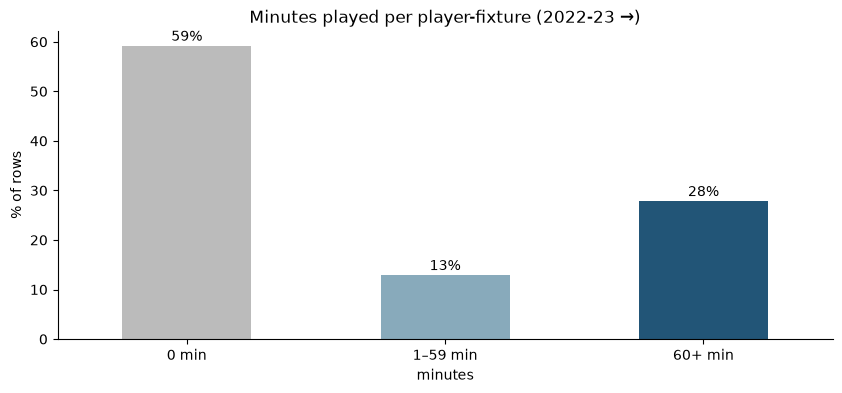

In [2]:
buckets = pd.cut(df.minutes, [-1, 0, 59, 200], labels=['0 min', '1–59 min', '60+ min'])
tab = buckets.value_counts(normalize=True).reindex(['0 min', '1–59 min', '60+ min']) * 100
ax = tab.plot.bar(color=['#bbb', '#8ab', '#257'], rot=0)
ax.set_ylabel('% of rows'); ax.set_title('Minutes played per player-fixture (2022-23 →)')
for i, v in enumerate(tab): ax.text(i, v + 1, f'{v:.0f}%', ha='center')
plt.show()

But "most rows are zero" is partly because squads include many fringe players nobody picks.
The real question is: **for a player who's been playing, how sure can we be he plays next time?**

In [3]:
d = df.sort_values(['player_id', 'kickoff_time']).copy()
g = d.groupby('player_id')
# starts over the PREVIOUS 5 fixtures (shift(1) = only past information)
d['starts_last5'] = g['minutes'].transform(lambda m: (m >= 60).astype(float).shift(1).rolling(5, min_periods=5).sum())
t = d.dropna(subset=['starts_last5']).groupby('starts_last5').agg(
        rows=('minutes', 'size'),
        p_plays=('played', 'mean'),
        p_60=('minutes', lambda m: (m >= 60).mean()))
t[['p_plays', 'p_60']] = (t[['p_plays', 'p_60']] * 100).round(1)
t

,rows,p_plays,p_60
starts_last5,,,
0.0,62878,12.7,3.5
1.0,9468,56.8,28.5
2.0,7860,66.0,41.6
3.0,7645,74.7,53.5
4.0,9058,83.5,69.0
5.0,15041,93.8,87.0


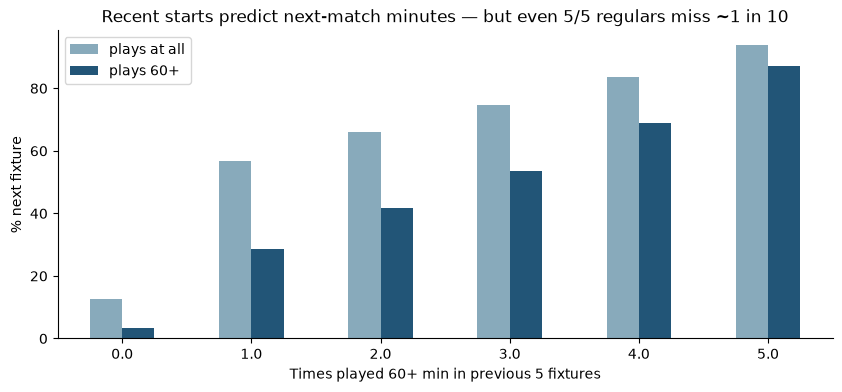

In [4]:
ax = t[['p_plays', 'p_60']].plot.bar(rot=0, color=['#8ab', '#257'])
ax.set_xlabel('Times played 60+ min in previous 5 fixtures'); ax.set_ylabel('% next fixture')
ax.set_title('Recent starts predict next-match minutes — but even 5/5 regulars miss ~1 in 10')
ax.legend(['plays at all', 'plays 60+']); plt.show()

**Takeaway:** recent playing time is a strong signal, but even nailed-on starters miss roughly
1 game in 10 (injury, rest, suspension). That uncertainty is the biggest driver of a player's expected points,
which is why the **minutes model comes first** and gets its own notebook (04).

## 2 · The shape of points (players who played)

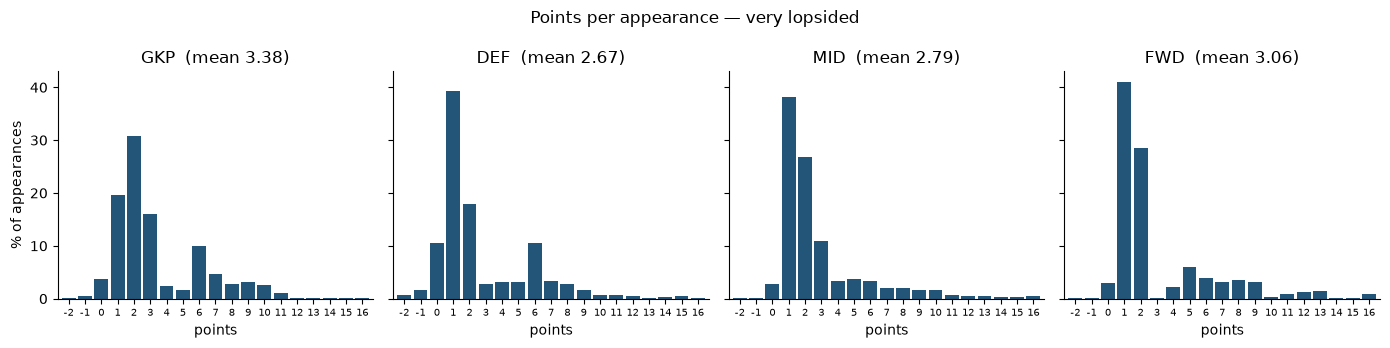

In [5]:
p = df[df.played]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5), sharey=True)
for ax, pos in zip(axes, POS_ORDER):
    s = p.loc[p.position == pos, 'fpl_points'].clip(-2, 16)
    s.value_counts(normalize=True).sort_index().mul(100).plot.bar(ax=ax, color='#257', width=0.85)
    ax.set_title(f'{pos}  (mean {p.loc[p.position == pos, "fpl_points"].mean():.2f})')
    ax.set_xlabel('points'); ax.tick_params(axis='x', labelsize=7, rotation=0)
axes[0].set_ylabel('% of appearances'); plt.suptitle('Points per appearance — very lopsided'); plt.tight_layout(); plt.show()

In [6]:
summary = p.groupby('position').fpl_points.agg(
    mean='mean', median='median',
    blank_le2=lambda s: (s <= 2).mean() * 100,
    return_ge4=lambda s: (s >= 4).mean() * 100,
    haul_ge10=lambda s: (s >= 10).mean() * 100).reindex(POS_ORDER).round(2)
summary

,mean,median,blank_le2,return_ge4,haul_ge10
position,,,,,
GKP,3.38,2.0,54.83,29.13,4.36
DEF,2.67,1.0,69.98,27.33,2.93
MID,2.79,2.0,68.11,20.91,4.62
FWD,3.06,2.0,72.75,27.03,5.16


**Takeaway:** the typical appearance is 1–2 points; a few hauls make a season. Two players with the
same *average* can be very different picks — a 6-point "safe" defender vs a midfielder who blanks
most weeks but hauls occasionally. That's why we output **P(return), P(5+), P(10+)**, not just an average,
and why we'll simulate full outcome distributions (notebook 08).

## 3 · Where do points come from?

Rebuilding each player's points from his stats with the scoring rules, then splitting them by source.
We use **2025-26**, the first season with defensive-contribution points. (This is also a preview of
notebook 01, where we'll check the scoring engine reproduces official points exactly.)

In [7]:
s = df[(df.season == '2025-26') & df.played].copy()
GOAL = {'GKP': 10, 'DEF': 6, 'MID': 5, 'FWD': 4}   # from bootstrap game_config.scoring (2026-27 config)
CS   = {'GKP': 4, 'DEF': 4, 'MID': 1, 'FWD': 0}
GC   = {'GKP': -1, 'DEF': -1, 'MID': 0, 'FWD': 0}
# FPL's defensive_contribution field is a COUNT of actions (CBIT for DEF, CBIRT for MID/FWD);
# it's worth 2 points only when it reaches the position threshold.
DC_THRESHOLD = {'GKP': np.inf, 'DEF': 10, 'MID': 12, 'FWD': 12}
parts = pd.DataFrame({
    'appearance': np.where(s.minutes >= 60, 2, 1),
    'goals':      s.goals * s.position.map(GOAL),
    'assists':    s.assists * 3,
    'clean sheet': s.clean_sheet * s.position.map(CS),
    'defensive contribution': 2 * (s.defensive_contribution >= s.position.map(DC_THRESHOLD)),
    'saves':      s.saves // 3,
    'bonus':      s.bonus,
    'conceded/cards/other': (s.goals_conceded // 2) * s.position.map(GC) - s.yellow_cards - 3 * s.red_cards
                            - 2 * s.own_goals - 2 * s.penalties_missed + 5 * s.penalties_saved,
}, index=s.index)
recon = parts.sum(axis=1)
print(f"Rebuilt points equal official points for {(recon == s.fpl_points).mean():.1%} of 2025-26 appearances")
share = parts.groupby(s.position).sum().reindex(POS_ORDER)
share = share.div(share.clip(lower=0).sum(axis=1), axis=0) * 100
share.round(1)

Rebuilt points equal official points for 100.0% of 2025-26 appearances


,appearance,goals,assists,clean sheet,defensive contribution,saves,bonus,conceded/cards/other
position,,,,,,,,
GKP,52.2,0.0,0.5,26.4,0.0,15.3,5.5,-12.2
DEF,49.4,5.8,5.0,23.3,11.6,0.0,4.8,-14.7
MID,52.8,16.3,10.9,6.1,7.2,0.0,6.7,-4.6
FWD,50.4,30.8,7.4,0.0,0.4,0.0,11.0,-3.3


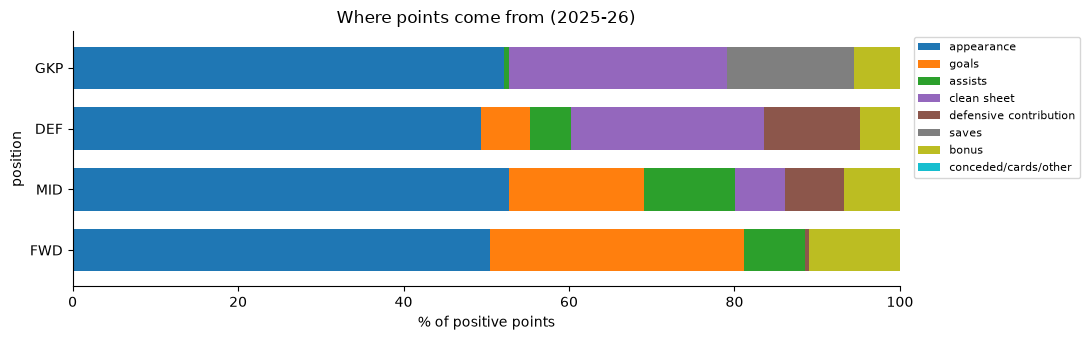

In [8]:
ax = share.clip(lower=0).plot.barh(stacked=True, figsize=(11, 3.5), colormap='tab10', width=0.7)
ax.invert_yaxis(); ax.set_xlabel('% of positive points'); ax.set_title('Where points come from (2025-26)')
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=8); plt.tight_layout(); plt.show()

**Takeaway:** appearance points are the single biggest slice for everyone — again, minutes matter most.
After that: **clean sheets** dominate for GK/DEF, **goals + assists** for MID/FWD, and **defensive
contributions** are now a real slice for defenders and midfielders. Note the defensive contribution stat is a *count*
of actions that only scores 2 points once it crosses a threshold (10 for DEF, 12 for MID/FWD) — so we'll model
the count and then the probability of crossing the line. Bonus is a steady ~10%. These are exactly the components
in our plan, and this chart tells us where accuracy is worth the most effort.

## 4 · How predictable is next week?

The simplest possible predictions, measured with **Mean Absolute Error** (MAE: on average, how many points
off are we?). Anything we build must beat these.

In [9]:
d = df.sort_values(['player_id', 'kickoff_time']).copy()
g = d.groupby('player_id')['fpl_points']
d['last1'] = g.shift(1)
d['last5_avg'] = g.transform(lambda x: x.shift(1).rolling(5, min_periods=1).mean())
d['season_avg'] = d.groupby(['player_id', 'season'])['fpl_points'].transform(lambda x: x.shift(1).expanding().mean())
d['zero'] = 0.0
ev = d.dropna(subset=['last1', 'last5_avg', 'season_avg'])
res = pd.DataFrame({name: [
        (ev[name] - ev.fpl_points).abs().mean(),
        (ev.loc[ev.played, name] - ev.loc[ev.played, 'fpl_points']).abs().mean()]
    for name in ['zero', 'last1', 'last5_avg', 'season_avg']}, index=['MAE all rows', 'MAE players who played']).T
res.round(3)

,MAE all rows,MAE players who played
zero,1.163,2.856
last1,1.152,2.533
last5_avg,1.059,2.133
season_avg,1.073,2.032


Note how **"predict zero for everyone"** looks competitive on all rows — because most rows are
non-players. That's a trap: a model can look good by being right about bench-warmers nobody would pick.
So we'll always judge models on **players who actually played** and on **players a manager would consider**
(e.g. regular starters), not only on all rows.

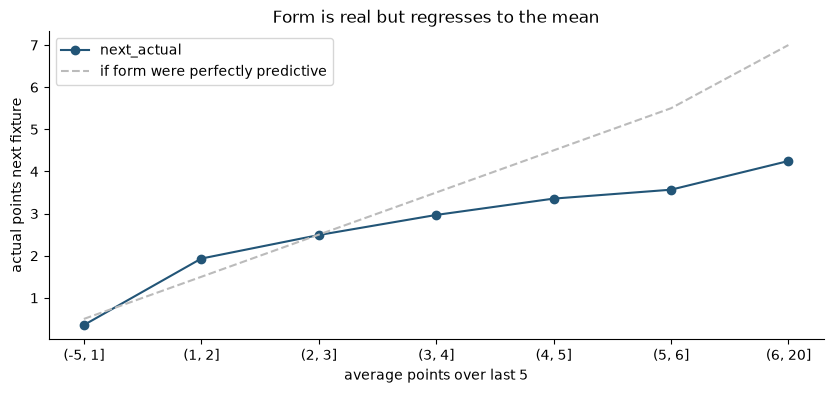

In [10]:
ev['corr_bucket'] = pd.cut(ev.last5_avg, [-5, 1, 2, 3, 4, 5, 6, 20])
c = ev.groupby('corr_bucket', observed=True).agg(n=('fpl_points', 'size'), next_actual=('fpl_points', 'mean'))
ax = c.next_actual.plot(marker='o', color='#257')
ax.plot(range(len(c)), [0.5, 1.5, 2.5, 3.5, 4.5, 5.5, 7], '--', color='#bbb', label='if form were perfectly predictive')
ax.set_xticks(range(len(c))); ax.set_xticklabels([str(i) for i in c.index], rotation=0)
ax.set_xlabel('average points over last 5'); ax.set_ylabel('actual points next fixture'); ax.legend()
ax.set_title('Form is real but regresses to the mean'); plt.show()

**Takeaway:** good recent form does predict more points next time, but much less than the raw form
suggests (*regression to the mean*: hot streaks cool off). Our models will lean on underlying numbers
(xG, xA, minutes, team strength, opponent) that are more stable than raw points.

## 5 · Does the opponent matter?

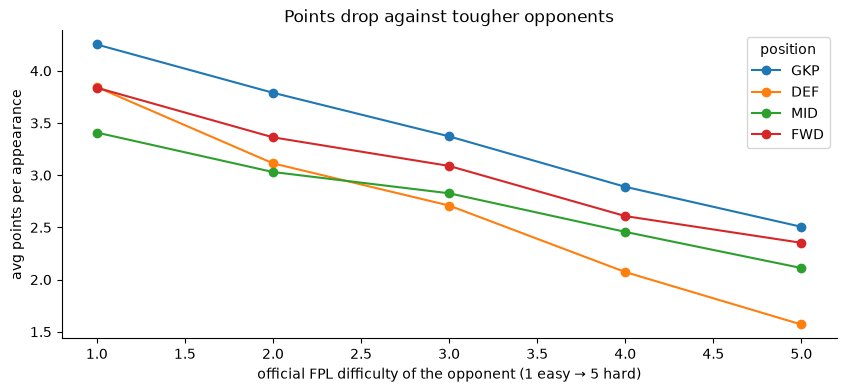

home vs away avg points (played):
was_home
False    2.65
True     2.99
Name: fpl_points, dtype: float64


In [11]:
f = p.groupby(['position', 'fdr']).fpl_points.mean().unstack(0)[POS_ORDER]
ax = f.plot(marker='o'); ax.set_xlabel("official FPL difficulty of the opponent (1 easy → 5 hard)")
ax.set_ylabel('avg points per appearance'); ax.set_title('Points drop against tougher opponents'); plt.show()
print('home vs away avg points (played):'); print(p.groupby('was_home').fpl_points.mean().round(2))

**Takeaway:** fixture difficulty matters a lot, more for defenders (clean sheets) than forwards.
Our own team-strength model (notebook 05) will replace the coarse official 1–5 rating with expected goals
for and against.

---
## ✅ Decisions for you before notebook 01

1. **Evaluation population.** How should we judge models? Options:
   *(a)* all rows, *(b)* only players who played, *(c)* "rotation-relevant" players, e.g. played in 3+ of the
   last 5 (closest to what a manager actually chooses from). We'd report all three; which one is the **headline** metric?
2. **Haul definition.** Use **5+** and **10+** points as the spec suggests, or something else (e.g. 6+ = a
   "return" with bonus)?
3. **Anything surprising** above that you want to dig into before we build the scoring engine?